# A transiting planet and an astrometric giant: the minimum mutual inclination

This notebook
1. simulates Gaia DR4 epoch astrometry and three precise radial-velocity (RV) datasets of a star with a short-period transiting planet and a long-period giant planet,
2. fits the astrometry and RVs jointly, with the transiting planet's inclination fixed at 90° (and its orbit circular),
3. samples the posterior with MCMC, and
4. derives the posterior of the minimum mutual inclination between the two orbits.

It needs `gaiamockplus`, `emcee` and `corner`. The MCMC takes about 3 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(1)           # random numbers for the simulation (reproducible)
M_JUP, M_EARTH = 1/1047.57, 3.003e-6      # Jupiter and Earth masses in Msun

## 1. Simulate the astrometry and the RVs

A Sun-like star at 25 pc hosts
- planet b: a 50 $M_\oplus$ planet on a circular 20-day orbit that transits, so its inclination is $i_b \approx 90°$. Its astrometric signal (about 0.001 mas) is far too small for Gaia, but its RV semi-amplitude (12 m/s) is easily measured.
- planet c: a 6 $M_\mathrm{J}$ planet on a 4-yr orbit, with a large astrometric signal (0.6 mas), of which the ~5.5-yr DR4 baseline covers more than one orbit.

The RVs come from three precise instruments (1, 1.5 and 2 m/s uncertainties, plus 1 m/s of jitter added in quadrature), all within 200 days: they resolve planet b, while planet c appears as a trend. The two orbits are far apart (period ratio ~70), so the system is dynamically stable. The true mutual inclination is 18°.

In [2]:
# the star: a Sun-like star at 25 pc
m_star = 1.0               # Msun
parallax = 40.0            # mas
phot_g_mean_mag = 6.6      # G magnitude of such a star at 25 pc
ra, dec = 120.0, -40.0     # deg
pmra, pmdec = -30.0, 45.0  # mas/yr

# the planets (b: transiting, c: astrometric giant)
planets = [dict(period=20.0, Tp=5.0, ecc=0.0, Omega=np.radians(120.0), inc=np.radians(90.0), w=0.0, m_planet=50*M_EARTH),
           dict(period=4.0*365.25, Tp=600.0, ecc=0.1, Omega=np.radians(130.0), inc=np.radians(75.0), w=np.radians(200.0), m_planet=6*M_JUP)]
names = ['b', 'c']

# Gaia DR4 astrometry
ast_data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                          planets=planets, phot_g_mean_mag=phot_g_mean_mag, data_release='dr4',
                                          c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = ast_data

# three precise RV datasets within 200 days: number of RVs and formal uncertainty (km/s)
n_rv = [20, 20, 20]
rv_err_set = [0.0010, 0.0015, 0.0020]
time_range = (0.5, 0.5 + 200/365.25)           # yr, relative to the reference epoch
gamma = np.array([-3.215, -3.190, -3.240])     # systemic velocity of each dataset (km/s)
jitter = 0.001                                 # km/s

t_rvs_yr = np.concatenate([np.sort(rng.uniform(*time_range, n)) for n in n_rv])
rv_dataset = np.repeat([0, 1, 2], n_rv)
rv_err = np.repeat(rv_err_set, n_rv)
rv = (gmp.rv_planets_model(t_rvs_yr, m_star, planets, gamma, c_funcs, rv_dataset=rv_dataset)
      + np.sqrt(rv_err**2 + jitter**2)*rng.normal(0, 1, len(t_rvs_yr)))
rv_data = (t_rvs_yr, rv, rv_err)

a0_true, K_true = gmp.get_planet_a0_mas(m_star, planets, parallax), gmp.get_planet_K_kms(m_star, planets)
print(f'astrometry: {len(t_ast_yr)} transits over {np.ptp(t_ast_yr):.1f} yr, median uncertainty {np.median(ast_err):.3f} mas; '
      f'RVs: {len(rv)} in {len(n_rv)} datasets over {365.25*np.ptp(t_rvs_yr):.0f} days')
for name, planet, a0, K in zip(names, planets, a0_true, K_true):
    print(f'planet {name}: P = {planet["period"]:.0f} d, a0 = {a0:.4f} mas, K = {1e3*K:.1f} m/s')

astrometry: 90 transits over 5.2 yr, median uncertainty 0.057 mas; RVs: 60 in 3 datasets over 196 days
planet b: P = 20 d, a0 = 0.0009 mas, K = 11.8 m/s
planet c: P = 1461 d, a0 = 0.5751 mas, K = 103.9 m/s


## 2. Fit the astrometry and RVs jointly

We know there are two planets (one from the transits, one from its astrometric orbit), so the joint fit uses `n_planets=2`. Some of planet b's parameters are held fixed with `fixed`, keyed by `<name>_<i>`, where `i` is the planet's index in order of period (planet b is 0):
- its inclination, at 90° (`inc_0`), from the transits. Its astrometry cannot constrain it: with the inclination free, the fit would hide a small, nearly face-on astrometric orbit in the noise;
- its eccentricity, at 0 (`ecc_0`): close-in planets are usually on circular orbits. (For a circular orbit, the phase and $\omega$ are degenerate, so the fitter also holds the phase at its best-fit value, and $\omega_b$ carries the orbital phase.) With $e_b$ free, the nearly degenerate phase and $\omega_b$ of a nearly circular orbit would also make the MCMC below mix very slowly;
- its $\Omega_b$ (`Omega_0`), which has no measurable effect (its astrometric signal is ~0.001 mas), at an arbitrary value.

Fixed parameters have zero uncertainty, and planet b's mass is now measured ($m_b = m_b \sin i_b$).

In [3]:
fixed = {'inc_0': np.pi/2, 'ecc_0': 0.0, 'Omega_0': 0.0}
res_joint = gmp.fit_astrometry_and_rv_planets(*ast_data, *rv_data, rv_dataset=rv_dataset, n_planets=2, m_star=m_star, fixed=fixed)
fit_b, fit_c = res_joint['planets']

print(f"consistency_delta = {res_joint['consistency_delta']:.1f}; jitter [m/s]: {np.round(1e3*res_joint['jitter'], 2)}")
print(f"\nplanet b          {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in [('P [d]', planets[0]['period'], fit_b['period'], fit_b['sig_period']),
                                  ('K [m/s]', 1e3*K_true[0], 1e3*fit_b['K'], 1e3*fit_b['sig_K']),
                                  ('m_p [M_Earth]', planets[0]['m_planet']/M_EARTH, fit_b['m_planet']/M_EARTH, fit_b['sig_m_planet']/M_EARTH)]:
    print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')
print(f"\nplanet c          {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in [('P [yr]', planets[1]['period']/365.25, fit_c['period']/365.25, fit_c['sig_period']/365.25),
                                  ('e', planets[1]['ecc'], fit_c['ecc'], fit_c['sig_ecc']),
                                  ('a0 [mas]', a0_true[1], fit_c['a0_mas'], fit_c['sig_a0_mas']),
                                  ('m_p [M_Jup]', planets[1]['m_planet']/M_JUP, fit_c['m_planet']/M_JUP, fit_c['sig_m_planet']/M_JUP),
                                  ('inc [deg]', 75.0, np.degrees(fit_c['inc']), np.degrees(fit_c['sig_inc'])),
                                  ('w [deg]', 200.0, np.degrees(fit_c['w']), np.degrees(fit_c['sig_w'])),
                                  ('Omega [deg]', 130.0, np.degrees(fit_c['Omega']), np.degrees(fit_c['sig_Omega']))]:
    print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')

consistency_delta = 1.4; jitter [m/s]: [0.87 0.98 0.  ]

planet b              true              fit
P [d]             20.000   19.995 +/- 0.031
K [m/s]           11.776   11.899 +/- 0.310
m_p [M_Earth]     50.000   50.519 +/- 1.324

planet c              true              fit
P [yr]             4.000    4.004 +/- 0.055
e                  0.100    0.110 +/- 0.017
a0 [mas]           0.575    0.572 +/- 0.012
m_p [M_Jup]        6.000    5.966 +/- 0.118
inc [deg]         75.000   74.903 +/- 1.608
w [deg]          200.000  199.449 +/- 9.007
Omega [deg]      130.000  129.881 +/- 1.460


Planet c's best-fit orbit on the sky (with planet b's tiny signal subtracted, as in notebook 04), and the RVs: planet b's signal (with planet c and the systemic velocities subtracted), planet c's trend (with planet b subtracted), and the residuals.

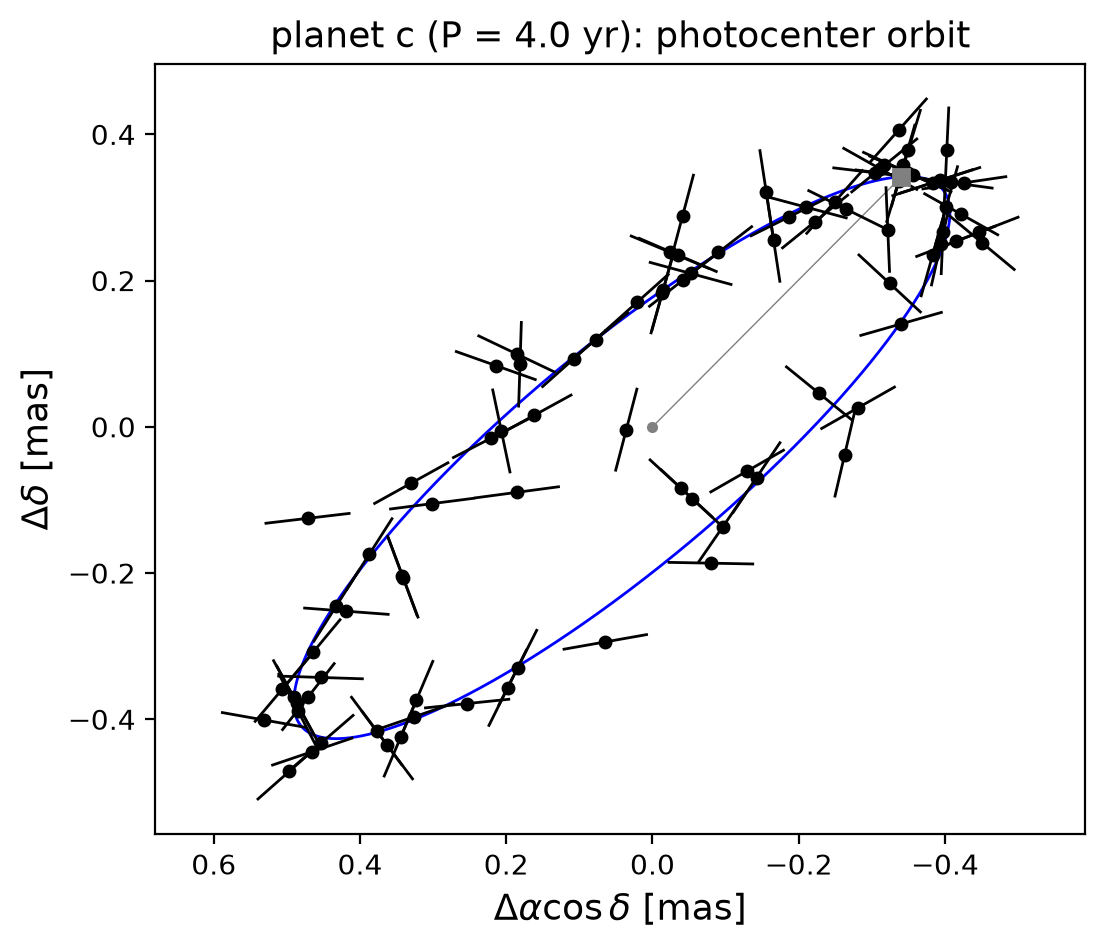

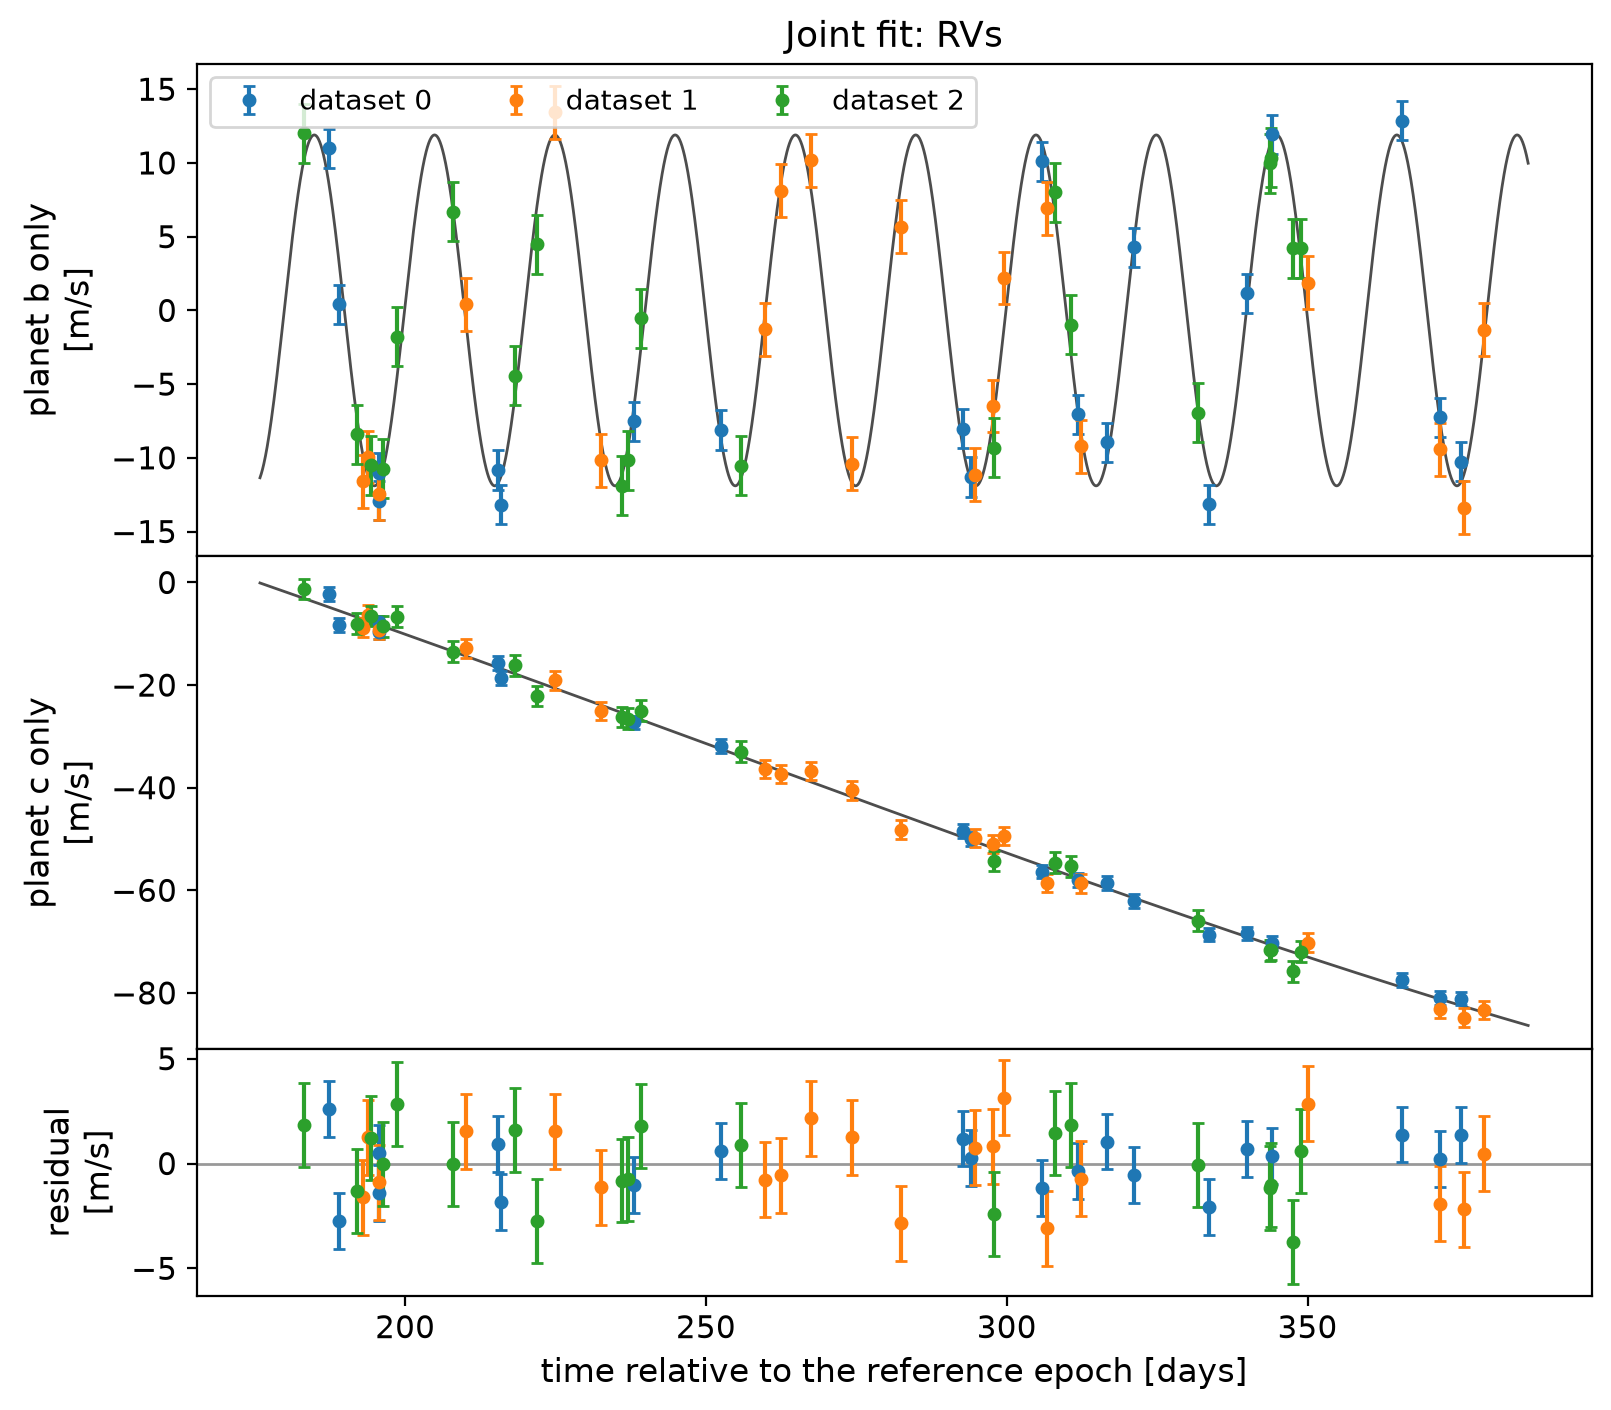

In [4]:
model, components = gmp.astrometry_planets_model(t_ast_yr, psi, plx_factor, res_joint['ra_off'], res_joint['dec_off'], res_joint['parallax'],
                                                 res_joint['pmra'], res_joint['pmdec'], m_star, res_joint['model_planets'], c_funcs,
                                                 return_components=True)
A, B, F, G = gmp.get_thiele_innes(fit_c['a0_mas'], fit_c['Omega'], fit_c['inc'], fit_c['w'])
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(t_ast_yr, psi, plx_factor, ast_obs - components[0], ast_err, period=fit_c['period'], ecc=fit_c['ecc'],
                                     Tp=fit_c['Tp'], delta_ra=res_joint['ra_off'], delta_dec=res_joint['dec_off'], parallax=res_joint['parallax'],
                                     pmra=res_joint['pmra'], pmdec=res_joint['pmdec'], A=A, B=B, F=F, G=G, data_release='dr4', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title(f'planet c (P = {fit_c["period"]/365.25:.1f} yr): photocenter orbit', fontsize=13)
plt.show()

t_grid = np.linspace(t_rvs_yr.min() - 0.02, t_rvs_yr.max() + 0.02, 3000)
_, curves = gmp.rv_planets_model(t_grid, m_star, res_joint['model_planets'], 0.0, c_funcs, return_components=True)
model_rv, comps = gmp.rv_planets_model(t_rvs_yr, m_star, res_joint['model_planets'], res_joint['gamma'], c_funcs, rv_dataset=rv_dataset, return_components=True)
err = np.sqrt(rv_err**2 + res_joint['jitter'][rv_dataset]**2)
days, days_grid = 365.25*t_rvs_yr, 365.25*t_grid
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 2, 1], hspace=0))
for i in range(2):
    axes[i].plot(days_grid, 1e3*curves[i], color='0.3', lw=1, zorder=0)
    for k in range(len(n_rv)):
        on = rv_dataset == k
        axes[i].errorbar(days[on], 1e3*(rv[on] - res_joint['gamma'][k] - comps[1 - i][on]), 1e3*err[on], fmt='o', ms=4, capsize=2, color=f'C{k}', label=f'dataset {k}')
    axes[i].set_ylabel(f'planet {names[i]} only\n[m/s]', fontsize=12)
for k in range(len(n_rv)):
    on = rv_dataset == k
    axes[2].errorbar(days[on], 1e3*(rv[on] - model_rv[on]), 1e3*err[on], fmt='o', ms=4, capsize=2, color=f'C{k}')
axes[2].axhline(0, color='0.6', lw=1, zorder=0)
axes[2].set_ylabel('residual\n[m/s]', fontsize=12)
axes[2].set_xlabel('time relative to the reference epoch [days]', fontsize=12)
axes[0].set_title('Joint fit: RVs', fontsize=13)
axes[0].legend(fontsize=10, ncol=3, loc='upper left')
for ax in axes:
    ax.tick_params(labelsize=11)
plt.show()

## 3. MCMC

As in notebook 04, `log_likelihood_astrometry_and_rv_planets` takes the full parameter vector (ordered like `res_joint['theta']`, followed by the jitters). With fixed parameters, the walkers sample only the free ones: `initial_walkers` starts them in a small ball around the best fit, in the free parameters (`res_joint['free_indices']`, then the jitters), and `full_theta` inserts the fixed values to give the full vector for the likelihood (and for the prior). The priors are uniform, as in notebook 04 (with the jitter below 20 m/s).

In [5]:
ast_err_mcmc = ast_err*res_joint['uncertainty_scale']

def log_prior(theta):
    P, e, inc, a0, jit = theta[5:19:7], theta[6:19:7], theta[9:19:7], theta[11:19:7], theta[22:]
    if (0 < theta[2] and np.all((10 < P) & (P < 1e4)) and P[0] < P[1] and np.all((0 <= e) & (e < 1)) and np.all((0 <= inc) & (inc <= np.pi))
            and np.all(a0 > 0) and np.all((0 <= jit) & (jit < 0.02))):
        return 0.0
    return -np.inf

def log_prob(theta_free):
    theta = gmp.full_theta(theta_free, res_joint)  # with the fixed parameters
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_and_rv_planets(theta, t_ast_yr, psi, plx_factor, ast_obs, ast_err_mcmc, *rv_data, rv_dataset=rv_dataset)

nwalkers, nsteps = 48, 40000
p0 = gmp.initial_walkers(res_joint, nwalkers, log_prob=lambda x: log_prior(gmp.full_theta(x, res_joint)), rng=rng)
np.random.seed(1)  # emcee draws its moves from numpy's global random state
sampler = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob)
sampler.run_mcmc(p0, nsteps, progress=True);

In [6]:
names_free = [res_joint['theta_names'][k] for k in res_joint['free_indices']] + ['jitter_0', 'jitter_1', 'jitter_2']
tau = sampler.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(names_free, tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples = np.array([gmp.full_theta(x, res_joint) for x in sampler.get_chain(discard=burn, thin=thin, flat=True)])  # full parameter vectors
print(f'{len(samples)} samples')

autocorrelation times [steps]: ra_off 422, dec_off 478, parallax 373, pmra 476, pmdec 424, period_0 411, w_0 401, a0_mas_0 409, period_1 529, ecc_1 467, phi_p_1 594, Omega_1 392, inc_1 398, w_1 588, a0_mas_1 421, gamma_0 411, gamma_1 412, gamma_2 405, jitter_0 415, jitter_1 442, jitter_2 448
chain length / longest autocorrelation time = 67
5952 samples


## 4. Corner plots

For planet b (with $i_b = 90°$, its mass is $m_b = m_b \sin i_b$; its eccentricity is fixed) and planet c, as in notebook 04. The red lines mark the true values.

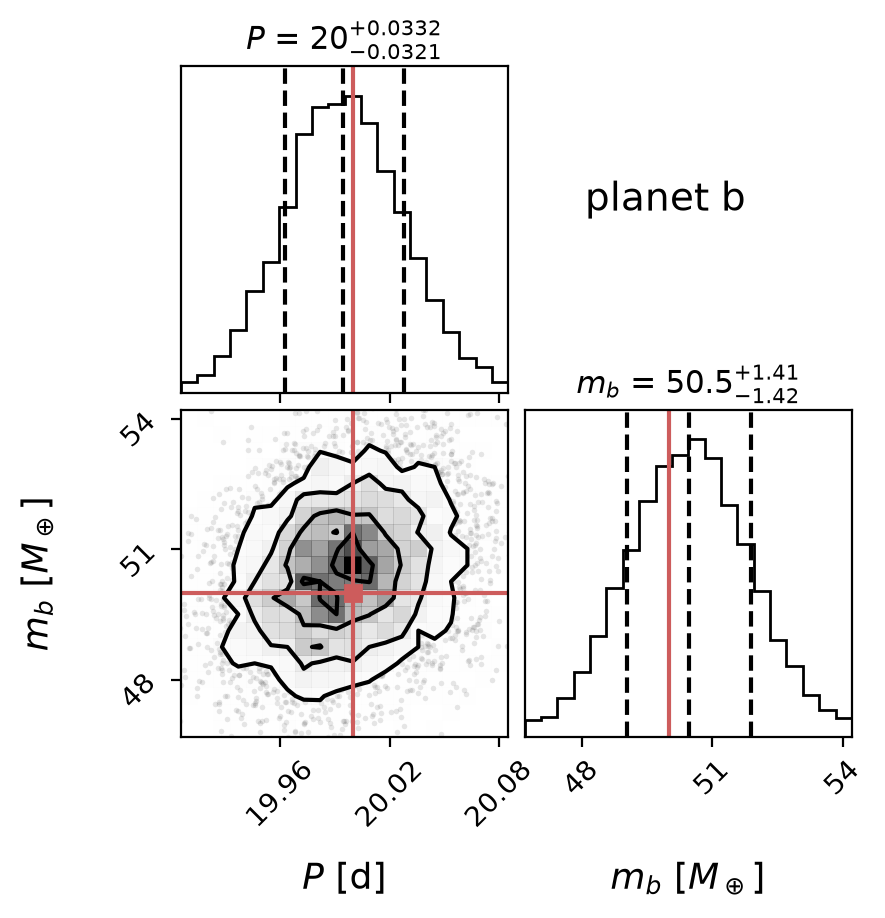

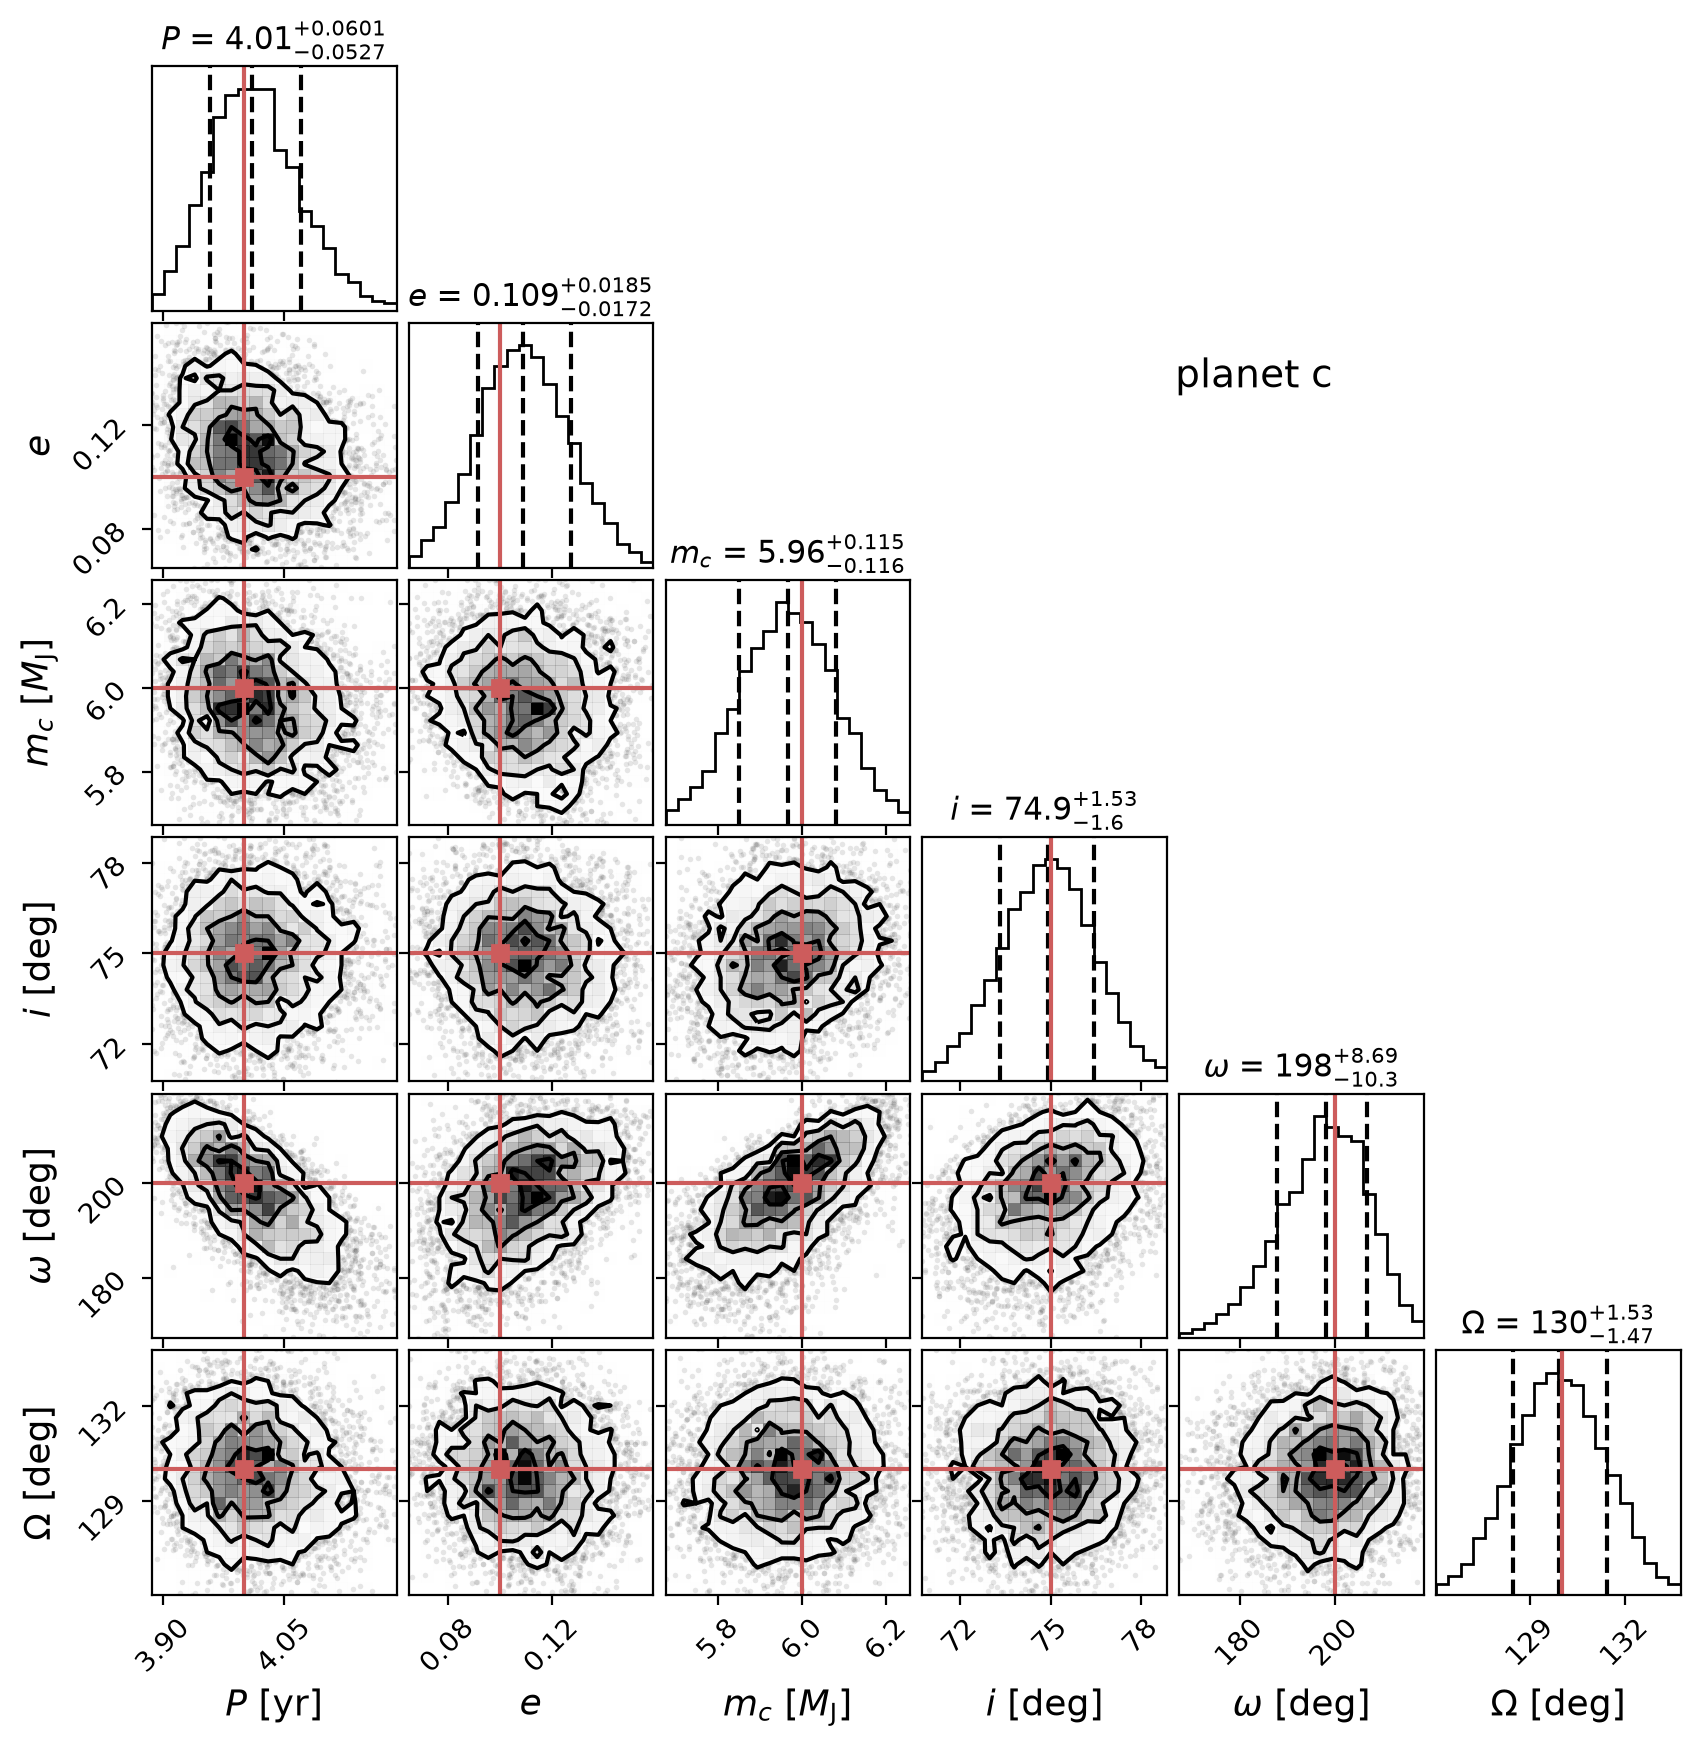

In [7]:
plx_s = samples[:, 2]
P_b, a0_b = samples[:, 5], samples[:, 11]
m_b = gmp.get_dark_companion_mass(a0_mas=a0_b, period=P_b, parallax=plx_s, m1=m_star)
corner_b = np.column_stack([P_b, m_b/M_EARTH])
fig = corner.corner(corner_b, range=[0.99]*2, labels=[r'$P$ [d]', r'$m_b$ [$M_\oplus$]'], titles=[r'$P$', r'$m_b$'],
                    truths=[planets[0]['period'], planets[0]['m_planet']/M_EARTH], truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08,
                    label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(4.5, 4.5)
fig.suptitle('planet b', fontsize=14, x=0.72, y=0.8)
plt.show()

P_c, e_c, a0_c, inc_c = samples[:, 12], samples[:, 13], samples[:, 18], samples[:, 16]
Omega_c = fit_c['Omega'] + np.angle(np.exp(1j*(samples[:, 15] - fit_c['Omega'])))  # keep the angles continuous around the best fit
w_c = fit_c['w'] + np.angle(np.exp(1j*(samples[:, 17] - fit_c['w'])))
m_c = gmp.get_dark_companion_mass(a0_mas=a0_c, period=P_c, parallax=plx_s, m1=m_star)
corner_c = np.column_stack([P_c/365.25, e_c, m_c/M_JUP, np.degrees(inc_c), np.degrees(w_c), np.degrees(Omega_c)])
fig = corner.corner(corner_c, range=[0.99]*6, labels=[r'$P$ [yr]', r'$e$', r'$m_c$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]'],
                    titles=[r'$P$', r'$e$', r'$m_c$', r'$i$', r'$\omega$', r'$\Omega$'],
                    truths=[planets[1]['period']/365.25, planets[1]['ecc'], planets[1]['m_planet']/M_JUP, 75.0, 200.0, 130.0], truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08,
                    label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(8.5, 8.5)
fig.suptitle('planet c', fontsize=14, x=0.72, y=0.8)
plt.show()

## 5. The minimum mutual inclination

The mutual inclination $\Phi$ of the two orbits satisfies
$$\cos\Phi = \cos i_b \cos i_c + \sin i_b \sin i_c \cos(\Omega_b - \Omega_c) = \sin i_c \cos(\Omega_b - \Omega_c) \quad (i_b = 90°).$$
$\Omega_b$ is unknown, so $\Phi$ itself is not constrained, but it can be no smaller than its value for $\Omega_b = \Omega_c$ (or $\Omega_c + 180°$): the minimum mutual inclination
$$\Phi_\mathrm{min} = |i_c - 90°|,$$
whose posterior follows from that of $i_c$. (Whether $i_b$ is slightly above or below 90° does not matter.)

minimum mutual inclination: 15.1 (+1.6 / -1.5) deg (true 15 deg; true mutual inclination 18 deg)
posterior probability that the orbits are misaligned by more than 5 deg: 1.0000
posterior probability that the orbits are misaligned by more than 10 deg: 0.9997


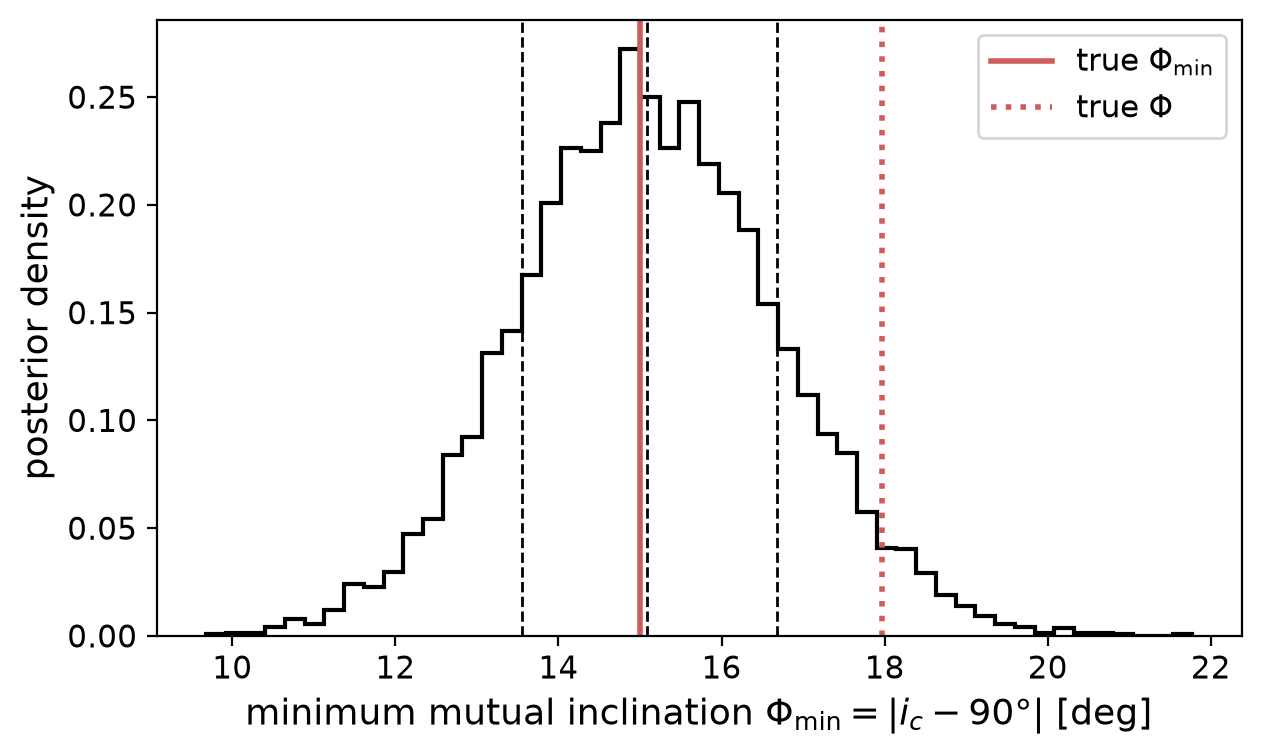

In [8]:
phi_min = np.abs(np.degrees(inc_c) - 90.0)
phi_min_true = abs(75.0 - 90.0)
p = planets
phi_true = np.degrees(np.arccos(np.cos(p[0]['inc'])*np.cos(p[1]['inc']) + np.sin(p[0]['inc'])*np.sin(p[1]['inc'])*np.cos(p[0]['Omega'] - p[1]['Omega'])))

lo, med, hi = np.percentile(phi_min, [16, 50, 84])
print(f'minimum mutual inclination: {med:.1f} (+{hi - med:.1f} / -{med - lo:.1f}) deg (true {phi_min_true:.0f} deg; true mutual inclination {phi_true:.0f} deg)')
for limit in (5, 10):
    print(f'posterior probability that the orbits are misaligned by more than {limit} deg: {np.mean(phi_min > limit):.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(phi_min, bins=50, histtype='step', color='k', lw=1.5, density=True)
ax.axvline(phi_min_true, color='indianred', lw=2, label=r'true $\Phi_\mathrm{min}$')
ax.axvline(phi_true, color='indianred', lw=2, ls=':', label=r'true $\Phi$')
for q in (lo, med, hi):
    ax.axvline(q, color='k', ls='--', lw=1)
ax.set_xlabel(r'minimum mutual inclination $\Phi_\mathrm{min} = |i_c - 90°|$ [deg]', fontsize=13)
ax.set_ylabel('posterior density', fontsize=13)
ax.tick_params(labelsize=11)
ax.legend(fontsize=11)
plt.show()